# Text Detection + Extraction

Goal: get text out of an image, in two steps. First find *where* the text is, then OCR each region. I started thinking I'd wire OpenCV's EAST text detector, but it needs a separate `frozen_east_text_detection.pb` download and I didn't want the notebook to die on someone else's machine. So detection is a simple contour-based region proposal, and recognition is `pytesseract`.

The images are real scanned business forms from FUNSD (Jaume et al., 2019; noisy scans from the RVL-CDIP tobacco document collection), loaded from the `nielsr/funsd-layoutlmv3` parquet on Hugging Face. FUNSD ships the ground-truth words for every form, so I can score the OCR instead of eyeballing it. I use the first 15 of the 50 test forms to keep tesseract runtime short.

Tesseract has to be installed at the system level (`brew install tesseract` on mac). I note that at the top because forgetting it is the #1 way this notebook dies for someone else.

In [1]:
# !pip install pytesseract pillow opencv-python -q
import io, re
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

try:
    import pytesseract
    TESS_OK = True
except Exception as e:
    print('pytesseract import failed:', e)
    TESS_OK = False

DATA = Path('../../data/funsd')
DATA.mkdir(parents=True, exist_ok=True)
np.random.seed(0)

## Load real scanned forms

Each FUNSD row has the page image plus its ground-truth word tokens and boxes. I only use the image and the token list.

15 forms, image size e.g. (1000, 754, 3), ground-truth words per form: 164 on average


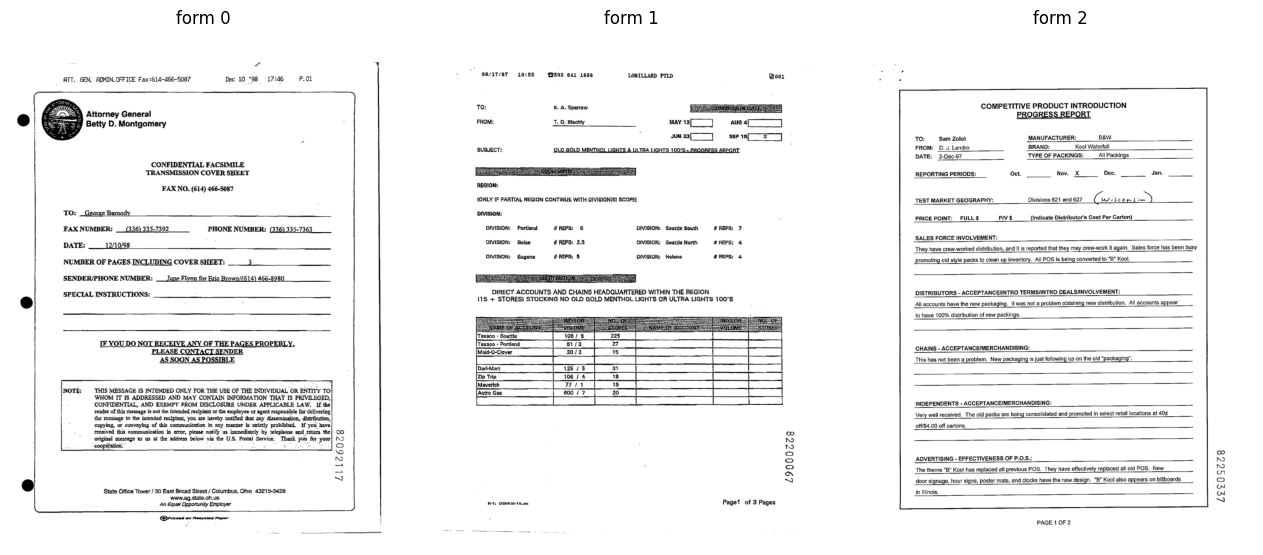

In [2]:
pq_path = DATA / "funsd_test.parquet"
if not pq_path.exists():
    pd.read_parquet("https://huggingface.co/datasets/nielsr/funsd-layoutlmv3/resolve/main/funsd/"
                    "test-00000-of-00001.parquet").to_parquet(pq_path)
forms = pd.read_parquet(pq_path).head(15)
docs = []
for _, r in forms.iterrows():
    img = np.array(Image.open(io.BytesIO(r["image"]["bytes"])).convert("RGB"))
    docs.append({"id": r["id"], "img": img, "words": list(r["tokens"])})
print(f"{len(docs)} forms, image size e.g. {docs[0]['img'].shape}, ground-truth words per form: "
      f"{int(np.mean([len(d['words']) for d in docs]))} on average")

samples = {d["id"]: d["img"] for d in docs[:3]}
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5))
for ax, (name, im) in zip(axes, samples.items()):
    ax.imshow(im); ax.set_title(f"form {name}"); ax.axis('off')
plt.tight_layout(); plt.show()

## Detection — cheap contour-based region proposal

EAST would be the right tool here; without the model file I fall back on classic CV: threshold, morphological close (so adjacent letters stick together), find contours, keep boxes that look text-shaped. Crude but transparent.

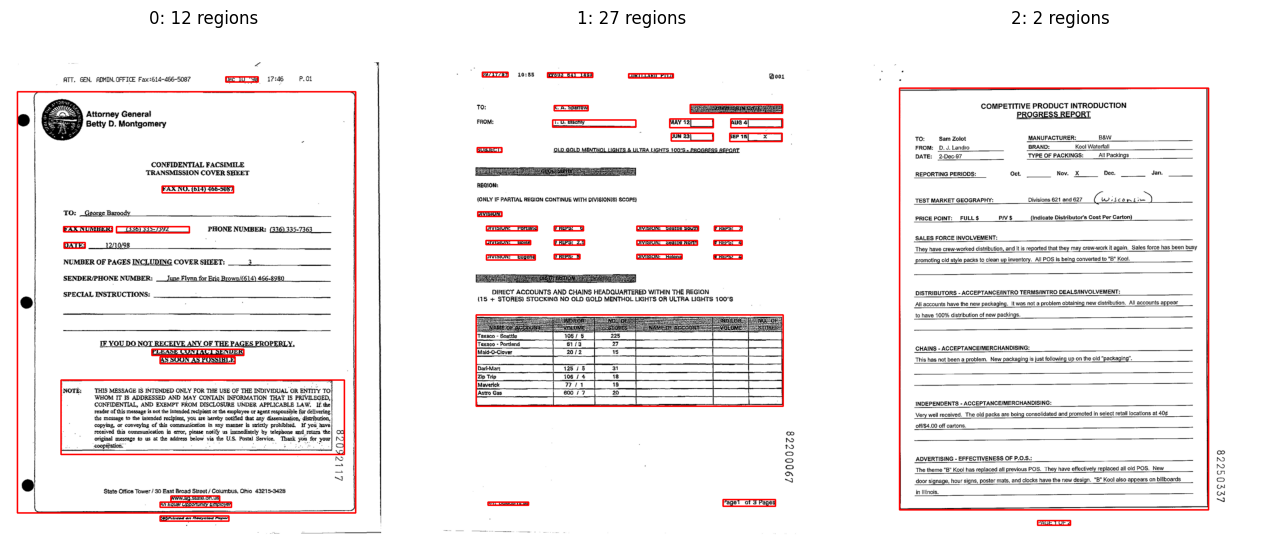

In [3]:
def detect_text_regions(img_rgb, min_area=400, min_ar=0.3, max_ar=15):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    # invert so text is white-on-black for morphology
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
    closed = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w * h < min_area: continue
        ar = w / max(h, 1)
        if not (min_ar < ar < max_ar): continue
        boxes.append((x, y, w, h))
    # sort top-to-bottom, left-to-right
    boxes.sort(key=lambda b: (b[1] // 20, b[0]))
    return boxes

def draw_boxes(img_rgb, boxes):
    out = img_rgb.copy()
    for (x, y, w, h) in boxes:
        cv2.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 2)
    return out

fig, axes = plt.subplots(1, 3, figsize=(13, 5.5))
for ax, (name, im) in zip(axes, samples.items()):
    bx = detect_text_regions(im)
    ax.imshow(draw_boxes(im, bx))
    ax.set_title(f'{name}: {len(bx)} regions'); ax.axis('off')
plt.tight_layout(); plt.show()

## Extraction, tesseract on each region

Two passes per form: once on the whole page and once region by region from the detector above. I score both with word recall against FUNSD's ground-truth words (lowercased, words of 2+ characters), so I can see whether region cropping actually helps.

In [4]:
def norm_words(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if len(w) > 1]

def word_recall(pred_text, truth_words):
    """Share of ground-truth words (2+ chars, lowercased) that appear in the OCR output."""
    truth = norm_words(" ".join(truth_words))
    pred = set(norm_words(pred_text))
    return sum(w in pred for w in truth) / max(len(truth), 1)

rows = []
if TESS_OK:
    for d in docs:
        im = d["img"]
        whole = pytesseract.image_to_string(im)
        per_region = []
        for (x, y, w, h) in detect_text_regions(im):
            crop = im[max(0, y - 4):y + h + 4, max(0, x - 4):x + w + 4]
            per_region.append(pytesseract.image_to_string(crop, config='--psm 7'))
        rows.append({"form": d["id"], "gt_words": len(d["words"]),
                     "recall_whole": word_recall(whole, d["words"]),
                     "recall_regions": word_recall(" ".join(per_region), d["words"])})
    res = pd.DataFrame(rows)
    print(res.round(3).to_string(index=False))
    print()
    print(f"mean word recall  whole image: {res.recall_whole.mean():.3f}   per region: {res.recall_regions.mean():.3f}")
    print("\nfirst 300 chars of whole-image OCR on the first form:")
    print(pytesseract.image_to_string(docs[0]["img"])[:300])
else:
    print('skipping OCR, pytesseract not available')

form  gt_words  recall_whole  recall_regions
   0       223         0.866           0.189
   1       167         0.575           0.315
   2       214         0.871           0.026
   3       222         0.407           0.231
   4       108         0.786           0.340
   5       187         0.848           0.064
   6       234         0.803           0.128
   7       228         0.424           0.204
   8       116         0.857           0.704
   9        70         0.892           0.600
  10        63         0.881           0.492
  11       190         0.550           0.190
  12       135         0.916           0.328
  13       112         0.658           0.137
  14       194         0.815           0.280

mean word recall  whole image: 0.743   per region: 0.282

first 300 chars of whole-image OCR on the first form:


4

AIT. GEN, ADMIN, OFFICE Fax:614-~466-S087 Dec 10 '98 17:06 P.Ot

EAA, Attomey General

CONFIDENTIAL FACSIMILE
‘TRANSMISSION COVER SHEET

FAX NO. (614) 466-5087

‘TO: _George Baroody
FAX NUMBER: (336) 335-7392. PHONE NUMBER: (336) 335-7363
DATE: 12/10/98 :

NUMBER OF PAGES INCLUDING COVER SHEET: 3


## Takeaways

On 15 real FUNSD forms, plain tesseract on the whole page recovers 74% of the ground-truth words on average (from 41% to 92% depending on the scan). My contour-detector-plus-crop pipeline does much worse, at 28%. So on real scanned forms the "detect, then OCR each region" idea, built this crudely, hurts instead of helping.

The detection plots above show why. The morphological close merges text with the form's ruled lines and borders, so on the third form the whole page frame becomes one giant region and most text lines get no box of their own, and on the second form the table turns into a single block. On top of that, tesseract's single-line mode (`--psm 7`) is a bad fit when a "region" actually holds several lines or a chunk of a table. Tesseract's own page segmentation already handles layout reasonably well on these scans.

What I'd try next: (1) a learned detector (EAST via `cv2.dnn.readNet`, or DBNet), (2) removing horizontal and vertical form lines before detection, (3) letting tesseract pick its own mode per crop (`--psm 6` or `11`) instead of forcing single-line. The FUNSD word boxes would also let me score detection on its own, separately from recognition.
